# PC Lab 11: Nonlinear dimensionality reduction with t-SNE and UMAP

In lab 10 you used PCA to reduce many features to a few. PCA is **linear**: every principal
component is a weighted sum of the original features, chosen to keep as much variance as possible.
That captures the large trends in the data well, but small groups of similar instances can end up
squashed on top of each other.

In the lecture you saw two **nonlinear** methods that take a different approach: instead of keeping
variance, they try to keep every instance close to its **neighbors**. These methods, t-SNE and UMAP,
are the standard way to visualize single-cell data: almost every single-cell paper contains a
t-SNE or UMAP plot. In this lab you make such plots yourself, and learn which parts of them you can
interpret and which you cannot.

### What you will be able to do after this lab

1. Compute t-SNE and UMAP embeddings, and explain why we run PCA first.
2. Describe how perplexity (t-SNE), `n_neighbors` and `min_dist` (UMAP) change the picture.
3. Say what a t-SNE or UMAP plot does tell you (which cells are neighbors) and what it does not
   (cluster sizes, distances between clusters).

In [1]:
%pip install -q umap-learn

import urllib.request
urllib.request.urlretrieve("https://raw.githubusercontent.com/BioML-UGent/MLLS/main/11_advanced_unsupervised/pancreas.csv.gz", "pancreas.csv.gz")

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

warnings.filterwarnings("ignore", module="umap")                     # harmless warnings from umap-learn
warnings.filterwarnings("ignore", message=".*ensure_all_finite.*")
RANDOM_STATE = 42

## 1. The data: 3,082 cells from the human pancreas

**Single-cell RNA sequencing** (scRNA-seq) counts, for every individual cell, the RNA molecules of
each gene. This shows which genes a cell is using, and therefore what kind of cell it is. One
experiment easily yields thousands of cells × 20,000 genes, far too many dimensions to look at
directly. That is why dimensionality reduction is one of the first steps of every single-cell
analysis.

The pancreas has two jobs. Most of it is **exocrine** tissue that makes digestive enzymes:
*acinar* cells produce the enzymes, and *ductal* cells line the ducts that carry them to the gut.
Scattered in between lie the **islets of Langerhans**, small clusters of **endocrine** cells
that release hormones into the blood: *alpha* cells (glucagon), *beta* cells (insulin), *delta*
cells (somatostatin), *gamma* cells (pancreatic polypeptide) and the rare *epsilon* cells
(ghrelin). Beta cells are the cells that are destroyed in type 1 diabetes. The tissue also
contains stellate cells (connective tissue; *activated* stellate cells are involved in
scarring), endothelial cells (blood vessels), Schwann cells (around nerves) and immune cells
(macrophages, mast cells and T cells).

We use the data of [Baron et al. (2016)](https://doi.org/10.1016/j.cels.2016.08.011), who
sequenced the pancreas cells of four human donors. The data have been prepared for you:

- at most 400 cells were kept per cell type, so that the most common cell types do not dominate
  (the numbers of cells in this file therefore do not reflect the composition of the pancreas);
- each cell was normalized to 10,000 counts in total and transformed with $\log(1 + x)$, so that
  cells that were sequenced more deeply can be compared with the others;
- only the 1,000 most variable genes were kept.

The column `cell_type` holds the cell type of each cell, as assigned by the authors based on
known marker genes. **None of the methods in this lab use these labels.** We only use them to
color the plots, so that we can check whether a method puts cells of the same type together. In a
new experiment you would not have the labels: finding the cell types is often exactly why you make
these plots.

<div class="alert alert-success">

<b>EXERCISE 1.1</b>: <b>Split the data into the gene expression matrix <code>X</code> and the
labels <code>y</code>, and count the cells of each type.</b> Which cell types are rare?
</div>

In [2]:
df = pd.read_csv("pancreas.csv.gz")    # one row per cell, one column per gene
y = df['cell_type'].values
X = df.drop(columns='cell_type').values
print("X:", X.shape)
print(df['cell_type'].value_counts())
# rare: the immune cells (55 macrophages, 25 mast cells, 7 T cells), 18 epsilon cells and 13 Schwann cells

X: (3082, 1000)
cell_type
acinar                400
beta                  400
ductal                400
delta                 400
alpha                 400
activated stellate    284
gamma                 255
endothelial           252
quiescent stellate    173
macrophage             55
mast                   25
epsilon                18
Schwann                13
T cell                  7
Name: count, dtype: int64


We will make many plots of cells in 2D, so here is a function that does it. Every cell type
always gets the same color, which makes the plots easy to compare.

In [3]:
CELL_TYPES = ['alpha', 'beta', 'delta', 'gamma', 'epsilon',                     # endocrine: hormones
              'acinar', 'ductal',                                                # exocrine: digestive enzymes
              'activated stellate', 'quiescent stellate', 'endothelial', 'Schwann',
              'macrophage', 'mast', 'T cell']                                    # immune cells
COLORS = dict(zip(CELL_TYPES, plt.cm.tab10.colors + plt.cm.tab20.colors[1::2]))

def plot_embedding(emb, title, ax=None, legend=True):
    """Scatter plot of a 2D embedding (one row per cell), colored by the cell types in y."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    for cell_type in CELL_TYPES:
        is_type = y == cell_type
        ax.scatter(emb[is_type, 0], emb[is_type, 1], s=4, color=COLORS[cell_type], label=cell_type)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])    # the axis values of t-SNE and UMAP have no meaning
    if legend:
        ax.legend(markerscale=3, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))

## 2. PCA as the starting point

Single-cell data are noisy: only a small fraction of the RNA molecules in a cell is captured, so
most entries of `X` are zero. The standard first step is therefore to keep the first ~50 principal
components. These hold most of the biological signal, while much of the noise is spread over the
many remaining directions. We will run t-SNE and UMAP on these 50 PCs instead of on the 1,000
genes. As a bonus, this makes them much faster, because they compute distances between cells in
50 instead of 1,000 dimensions.

(Unlike in lab 10, we do not standardize the genes first. After the log-transformation they are on
a comparable scale, and standardizing would blow up genes that are expressed in only a handful of
cells.)

<div class="alert alert-success">

<b>EXERCISE 2.1</b>: <b>Compute the first 50 principal components of <code>X</code> and plot the
cells on the first two.</b> How much of the variance do the 50 PCs explain together?
</div>

variance explained by 50 PCs: 0.66


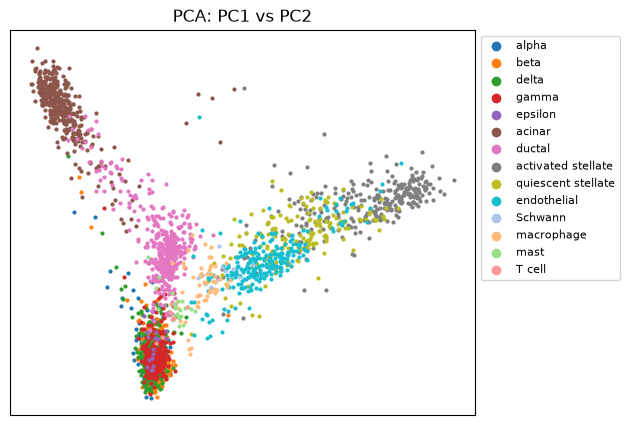

In [4]:
pca = PCA(n_components=50, random_state=RANDOM_STATE).fit(X)
X_pca = pca.transform(X)
print(f"variance explained by 50 PCs: {pca.explained_variance_ratio_.sum():.2f}")

plot_embedding(X_pca[:, :2], "PCA: PC1 vs PC2")
plt.show()

## 3. t-SNE

A short recap of the lecture. t-SNE first turns the distances between cells into probabilities
$p_{j|i}$ that cell $i$ would pick cell $j$ as its neighbor, using a Gaussian centered on cell $i$
(these are then symmetrized into $p_{ij}$).
The width of each Gaussian is chosen such that every cell has roughly the same effective number of
neighbors: the **perplexity**. Then t-SNE places the cells in 2D, computes similarities $q_{ij}$ there
with a heavy-tailed Student-$t$ distribution, and moves the cells by gradient descent until the
$q_{ij}$ match the $p_{ij}$ as well as possible (it minimizes the KL divergence).

Only neighborhoods enter this objective. So t-SNE does its best to keep neighbors together, but
it is free to move whole clusters around and to stretch or shrink them.

<div class="alert alert-success">

<b>EXERCISE 3.1</b>: <b>Compute a 2D t-SNE embedding of the 50 PCs, with perplexity 30.</b> The
plot compares it with PCA.
</div>

t-SNE took 8.9 s


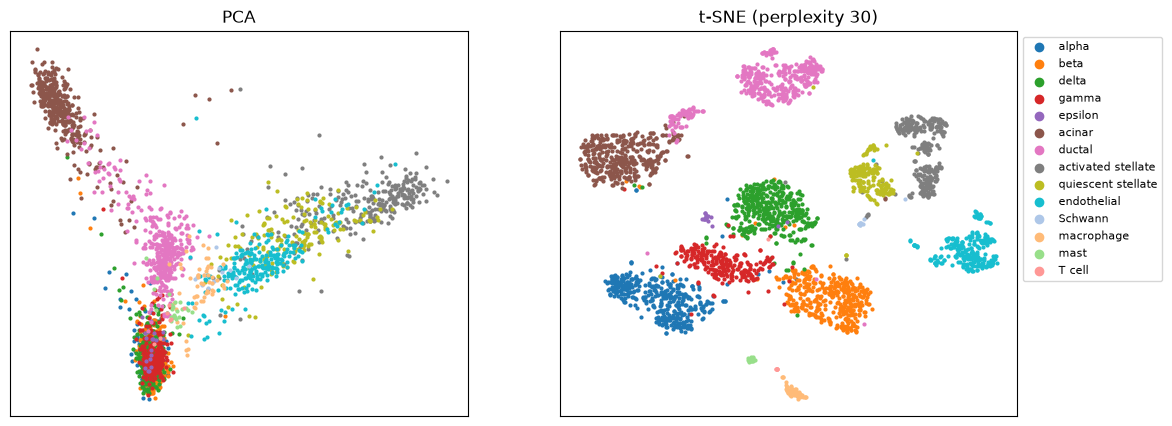

In [5]:
start = time.time()
X_tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE).fit_transform(X_pca)
print(f"t-SNE took {time.time() - start:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_embedding(X_pca[:, :2], "PCA", ax=axes[0], legend=False)
plot_embedding(X_tsne, "t-SNE (perplexity 30)", ax=axes[1])
plt.show()

<div class="alert alert-success">

<b>EXERCISE 3.2</b>: <b>Repeat t-SNE with perplexity 5, 30 and 300.</b> This takes a minute or
two.
</div>

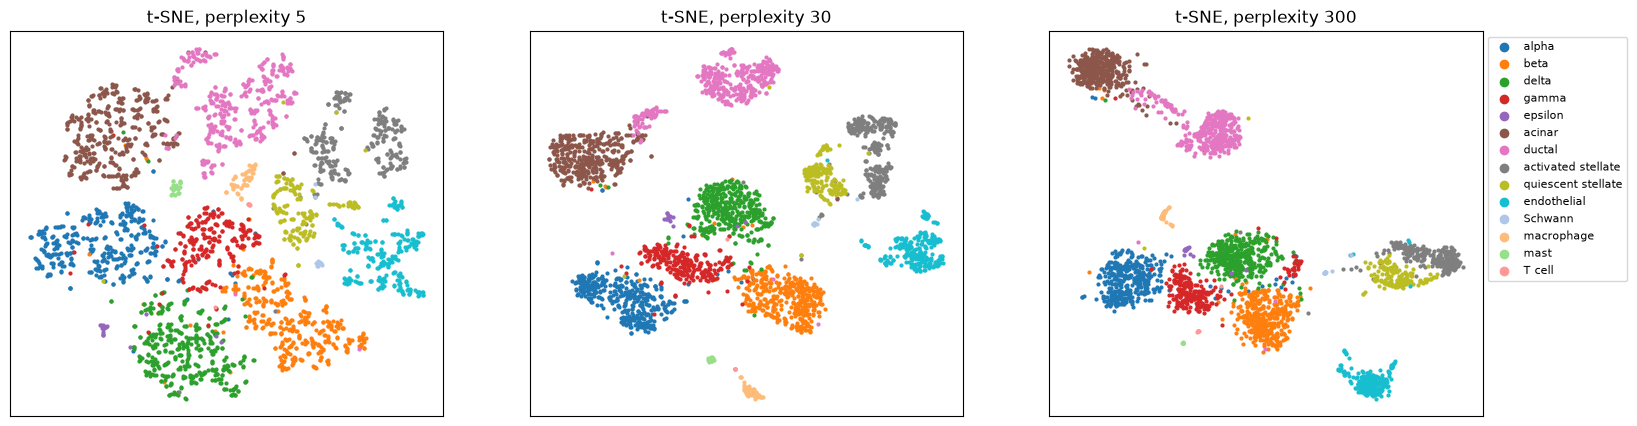

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, perplexity in zip(axes, [5, 30, 300]):
    emb = TSNE(n_components=2, perplexity=perplexity, random_state=RANDOM_STATE).fit_transform(X_pca)
    plot_embedding(emb, f"t-SNE, perplexity {perplexity}", ax=ax, legend=(ax is axes[-1]))
plt.show()

<div class="alert alert-info">

<b>Think about it.</b>

1. Perplexity is roughly the number of neighbors that each cell takes into account. What happens
   with a very small perplexity, and with a very large one?
2. In the PCA plot, the hormone-producing cells are packed into a small spot, while the acinar
   and ductal cells are spread out. In the t-SNE plot, the islands of alpha, beta, delta, acinar
   and ductal cells (400 cells each) are about equally large. Which of the two plots tells you
   how different the cells *within* a cell type are? (Hint: every cell gets the same effective
   number of neighbors.)
</div>

**Answer.** (Your plots may look slightly different from the ones here, depending on your computer and package versions, but the trends are the same.)

1. With perplexity 5, each cell only looks at its few closest cells. Several cell types fall apart into small pieces (the ductal and the stellate cells), and the gaps between cell types become small. Do not mistake such pieces for subtypes: they can simply be an artifact of looking too locally. With perplexity 300, each cell takes 300 neighbors into account: the islands become more compact, and related cell types move next to each other (the acinar cells are connected to the ductal cells, and the hormone-producing cells form one row). It is also slower. The default of 30 is a reasonable compromise, but there is no single right value, so always look at more than one.

2. The PCA plot. Because every cell gets the same effective number of neighbors, t-SNE makes the Gaussians narrow in dense regions and wide in sparse regions. That evens out the densities: a tight cluster is expanded and a loose one is shrunk. The area of an island in a t-SNE plot therefore mostly reflects how *many* cells it contains, not how variable they are. PCA is a linear projection, so a spot that is small in the PCA plot does mean that these cells are similar (at least along PC1 and PC2).

## 4. UMAP

UMAP builds a graph that connects every cell to its `n_neighbors` nearest neighbors, with
weights that decrease with distance. It then searches for a 2D layout with a similar graph, by
pulling connected cells together and pushing unconnected cells apart. `min_dist` sets how close
cells may be packed in 2D: small values give tight clumps, large values spread the cells out.

Unlike t-SNE, UMAP learns a mapping from the input space to 2D, so it can also place new cells
with `.transform()`. UMAP is not part of scikit-learn, but the `umap-learn` package follows the
same interface.

<div class="alert alert-success">

<b>EXERCISE 4.1</b>: <b>Compute a 2D UMAP embedding of the 50 PCs, with the default settings
<code>n_neighbors=15</code> and <code>min_dist=0.1</code>.</b> The first run takes a few seconds
longer, because umap-learn compiles its code.
</div>

UMAP took 12.1 s


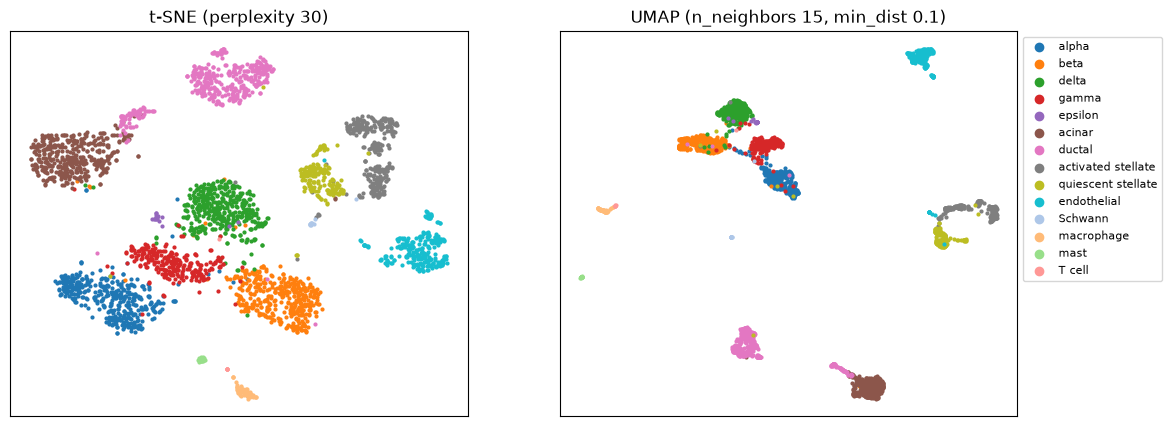

In [7]:
start = time.time()
X_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(X_pca)
print(f"UMAP took {time.time() - start:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_embedding(X_tsne, "t-SNE (perplexity 30)", ax=axes[0], legend=False)
plot_embedding(X_umap, "UMAP (n_neighbors 15, min_dist 0.1)", ax=axes[1])
plt.show()

<div class="alert alert-success">

<b>EXERCISE 4.2</b>: <b>Run UMAP with three other settings: fewer neighbors, more neighbors, and
a larger <code>min_dist</code>.</b>
</div>

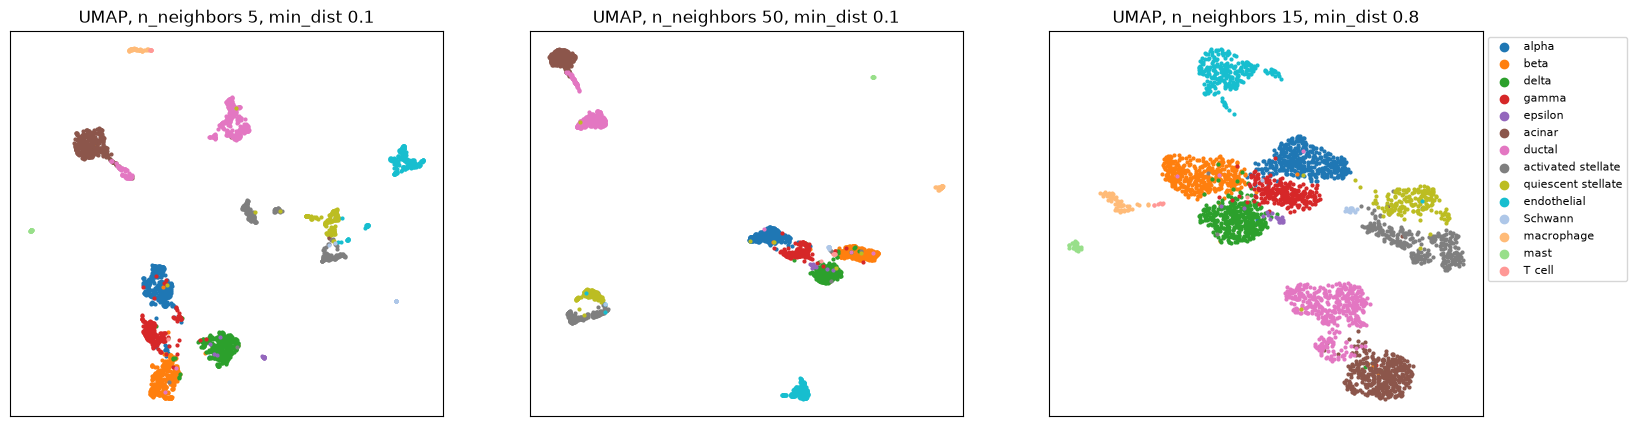

In [8]:
settings = [(5, 0.1), (50, 0.1), (15, 0.8)]      # (n_neighbors, min_dist)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (n_neighbors, min_dist) in zip(axes, settings):
    emb = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, random_state=RANDOM_STATE).fit_transform(X_pca)
    plot_embedding(emb, f"UMAP, n_neighbors {n_neighbors}, min_dist {min_dist}", ax=ax, legend=(ax is axes[-1]))
plt.show()

<div class="alert alert-info">

<b>Think about it.</b>

1. Compare `n_neighbors` 5 and 50: what happens to the hormone-producing cells (alpha to
   epsilon) and to the stellate cells? What does a larger `min_dist` change, and what does it
   not change?
2. Which cell types end up close to each other in the t-SNE and UMAP plots? Does that make
   biological sense? Can you tell from the plots how far apart these groups really are?
</div>

**Answer.** 1. With 5 neighbors, UMAP looks very locally: the delta cells form a separate island, the alpha, gamma and beta cells a chain of separate clumps, and the stellate and endothelial cells break up into several small pieces. With 50 neighbors, the hormone-producing cell types merge into one continuous band, and the activated and quiescent stellate cells into one island. So `n_neighbors` decides which cells are grouped together: small values favor fine detail (and can split real groups into pieces), large values favor the bigger picture. A larger `min_dist` does not change which cells are grouped together: the same groups appear, only less tightly packed. (With the default `min_dist=0.1`, the clusters are packed so tightly that they look much more homogeneous than they are.)

2. Cell types with a related function end up close together: the five hormone-producing cell types form one group, the acinar cells are connected to the ductal cells (both exocrine), and the activated and quiescent stellate cells lie next to each other. That makes biological sense. The macrophages and mast cells form small separate islands. But the plots do not tell you how far apart these groups really are. The positions of the groups change from one UMAP setting to the next, and both methods only try to keep neighbors together, not to keep distant groups at the right distance.

<div class="alert alert-warning">

<b>Take-home messages</b>

- PCA is linear and keeps the global structure. t-SNE and UMAP are nonlinear and keep local
  neighborhoods, which makes small populations visible.
- In single-cell analysis, run t-SNE and UMAP on the top ~50 PCs: less noise, and much faster.
- The result depends on the hyperparameters (perplexity; `n_neighbors` and `min_dist`) and on
  the random seed. Try more than one setting before you draw conclusions.
- Read *which cells are neighbors*. Do not read cluster sizes or distances between clusters.
- t-SNE and UMAP are for visualization. For further analysis, use the PCs or the original data.
</div>